<a href="https://colab.research.google.com/github/FaizMi16/Project_Kelompok_Laptop_Price/blob/main/Implementasi_EDA%20dan%20Preprocesing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 0 — Setup Environment

In [7]:
# Install jika belum
# pip install pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

# Load dataset (encoding latin-1 karena ada karakter khusus)
df = pd.read_csv('laptop_price.csv', encoding='latin-1')

print("Shape:", df.shape)
print(df.head())
print(df.info())

Shape: (1303, 13)
   laptop_ID Company      Product   TypeName  Inches  \
0          1   Apple  MacBook Pro  Ultrabook    13.3   
1          2   Apple  Macbook Air  Ultrabook    13.3   
2          3      HP       250 G6   Notebook    15.6   
3          4   Apple  MacBook Pro  Ultrabook    15.4   
4          5   Apple  MacBook Pro  Ultrabook    13.3   

                     ScreenResolution                         Cpu   Ram  \
0  IPS Panel Retina Display 2560x1600        Intel Core i5 2.3GHz   8GB   
1                            1440x900        Intel Core i5 1.8GHz   8GB   
2                   Full HD 1920x1080  Intel Core i5 7200U 2.5GHz   8GB   
3  IPS Panel Retina Display 2880x1800        Intel Core i7 2.7GHz  16GB   
4  IPS Panel Retina Display 2560x1600        Intel Core i5 3.1GHz   8GB   

                Memory                           Gpu  OpSys  Weight  \
0            128GB SSD  Intel Iris Plus Graphics 640  macOS  1.37kg   
1  128GB Flash Storage        Intel HD Graphics 6000

Step 1 — Inspeksi Struktur Data

In [ ]:
# Cek tipe data & missing value
print("=== INFO ===")
print(df.info())

print("\n=== MISSING VALUE ===")
print(df.isnull().sum())

print("\n=== DUPLIKAT ===")
print("Jumlah duplikat:", df.duplicated().sum())

print("\n=== STATISTIK DESKRIPTIF ===")
print(df.describe())

Step 2 — EDA Univariat: Distribusi Harga

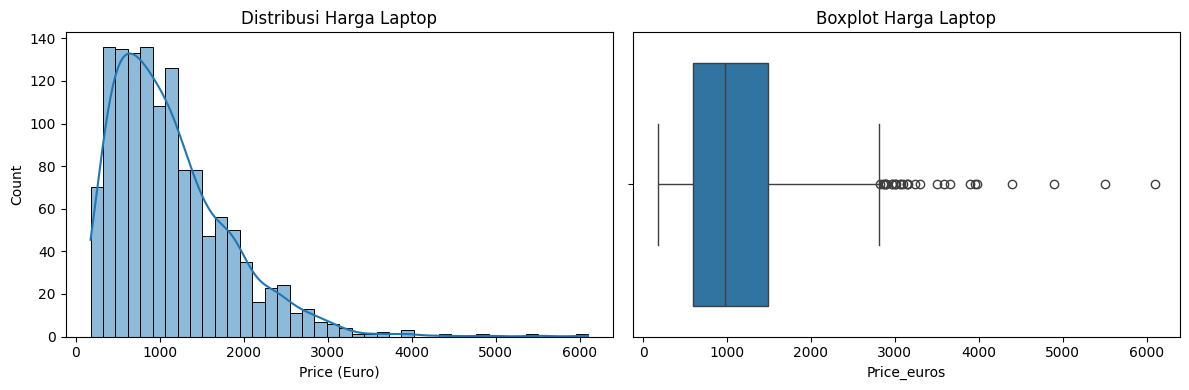

Skewness: 1.5208655681688525


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
sns.histplot(df['Price_euros'], kde=True, bins=40, ax=axes[0])
axes[0].set_title('Distribusi Harga Laptop')
axes[0].set_xlabel('Price (Euro)')

# Boxplot
sns.boxplot(x=df['Price_euros'], ax=axes[1])
axes[1].set_title('Boxplot Harga Laptop')

plt.tight_layout()
plt.show()

# Cek skewness
print("Skewness:", df['Price_euros'].skew())

Step 3 — EDA Univariat: Kolom Kategorikal

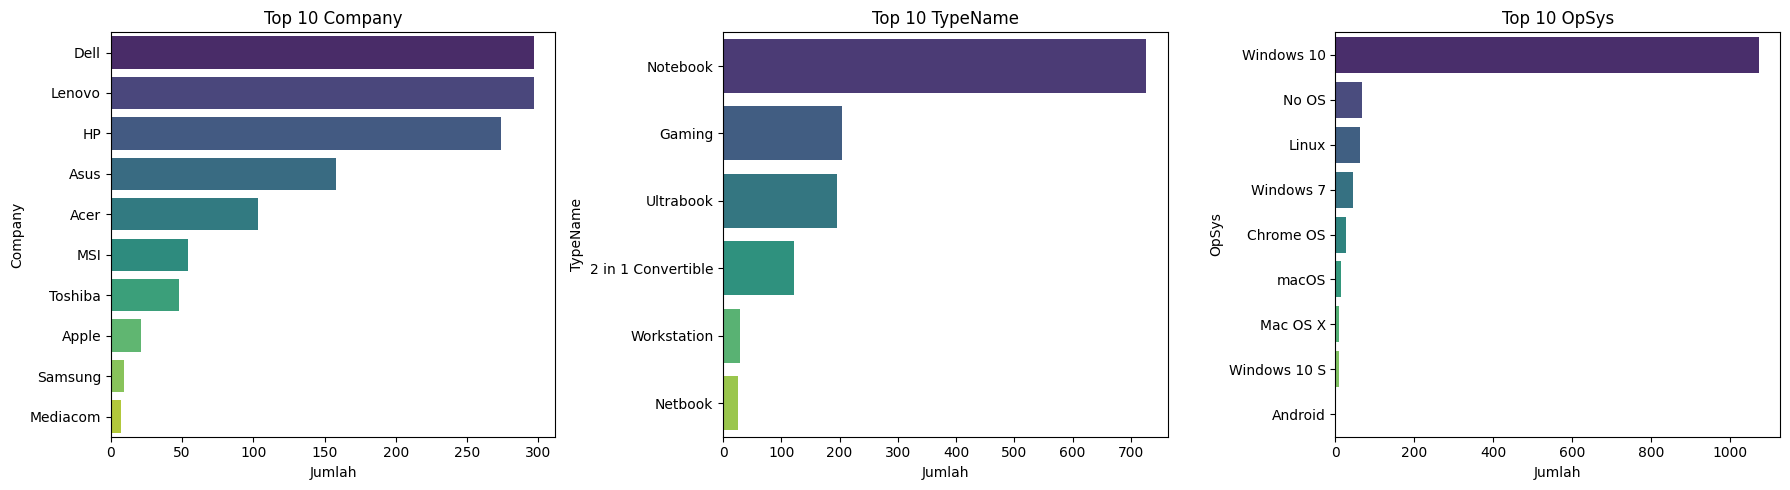

Company: 19 kategori unik
TypeName: 6 kategori unik
OpSys: 9 kategori unik


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['Company', 'TypeName', 'OpSys']):
    top = df[col].value_counts().head(10)
    sns.barplot(x=top.values, y=top.index, ax=ax, palette='viridis')
    ax.set_title(f'Top 10 {col}')
    ax.set_xlabel('Jumlah')

plt.tight_layout()
plt.show()

# Tampilkan jumlah unik
for col in ['Company', 'TypeName', 'OpSys']:
    print(f"{col}: {df[col].nunique()} kategori unik")

Step 4 — EDA Bivariat: Hubungan dengan Harga

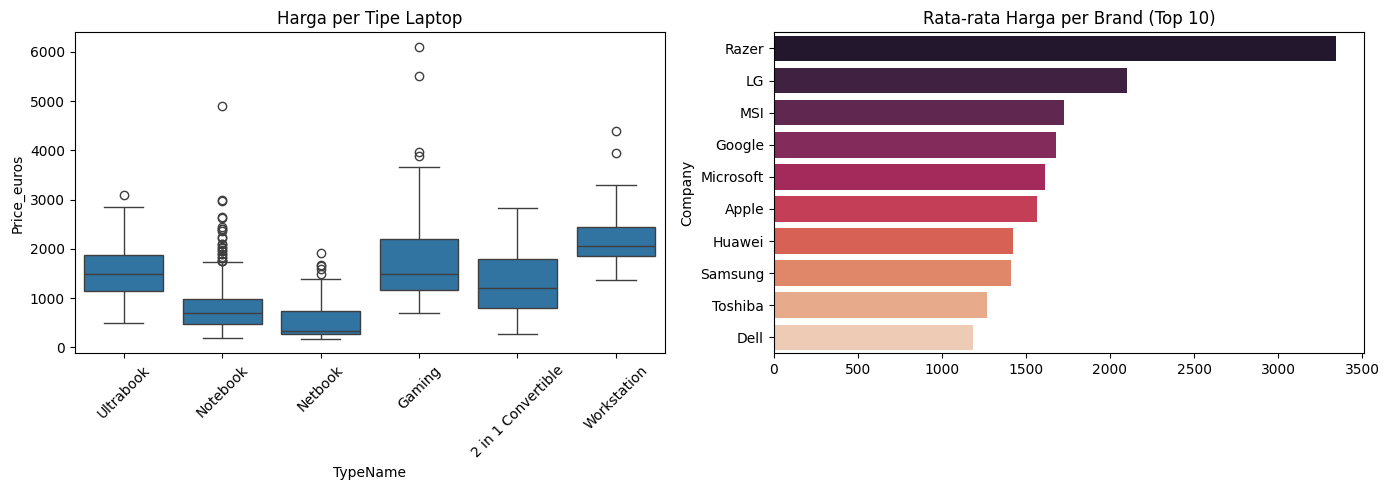

               Inches  Price_euros
Inches       1.000000     0.068197
Price_euros  0.068197     1.000000


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Harga per tipe laptop
sns.boxplot(x='TypeName', y='Price_euros', data=df, ax=axes[0])
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
axes[0].set_title('Harga per Tipe Laptop')

# Rata-rata harga per brand (top 10 termahal)
brand_price = df.groupby('Company')['Price_euros'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=brand_price.values, y=brand_price.index, ax=axes[1], palette='rocket')
axes[1].set_title('Rata-rata Harga per Brand (Top 10)')

plt.tight_layout()
plt.show()

# Korelasi numerik
print(df[['Inches', 'Price_euros']].corr())

Step 5 — EDA Bivariat: RAM & Ukuran Layar vs Harga

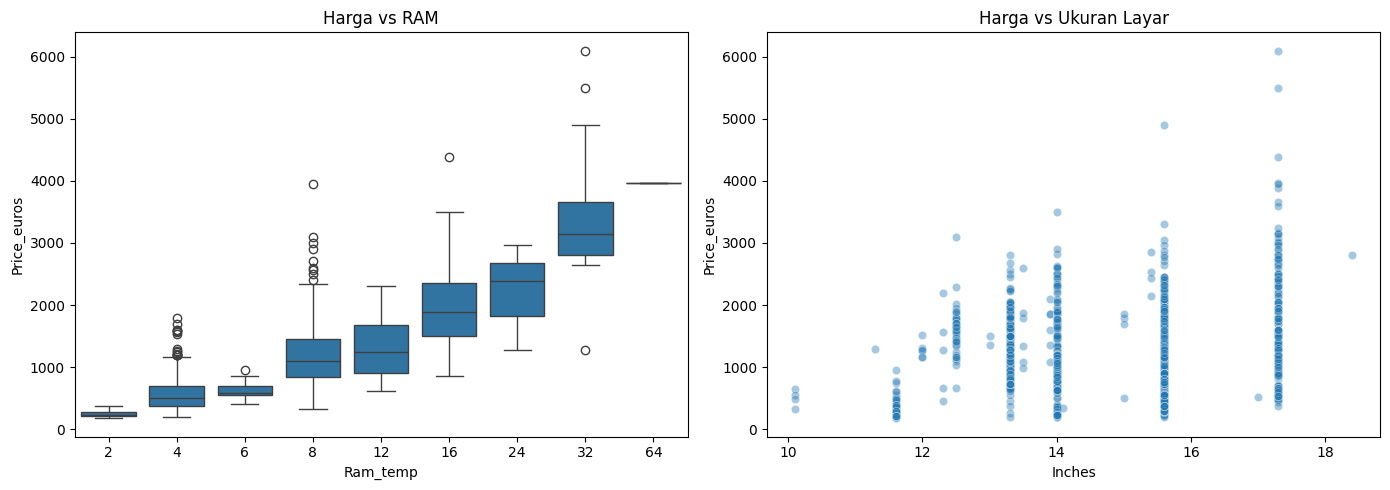

In [11]:
# Karena Ram masih string, kita parsing sementara untuk EDA
df['Ram_temp'] = df['Ram'].str.replace('GB', '').astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='Ram_temp', y='Price_euros', data=df, ax=axes[0])
axes[0].set_title('Harga vs RAM')

sns.scatterplot(x='Inches', y='Price_euros', data=df, alpha=0.4, ax=axes[1])
axes[1].set_title('Harga vs Ukuran Layar')

plt.tight_layout()
plt.show()

df.drop(columns=['Ram_temp'], inplace=True)  # hapus kolom sementara

TAHAP 1: EXPLORATORY DATA ANALYSIS (EDA)

In [12]:
# 1. Cek Missing Values
print("=== JUMLAH MISSING VALUE PER KOLOM ===")
print(df.isnull().sum())

# 2. Cek Duplikat
print("\nJumlah baris duplikat:", df.duplicated().sum())

=== JUMLAH MISSING VALUE PER KOLOM ===
laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
dtype: int64

Jumlah baris duplikat: 0


In [13]:
n = df.nunique()
print("Kolom konstan (isinya sama semua):", list(n[n <= 1].index))
print("Kolom Identifier (unik tiap baris):", list(n[n == len(df)].index))

Kolom konstan (isinya sama semua): []
Kolom Identifier (unik tiap baris): ['laptop_ID']


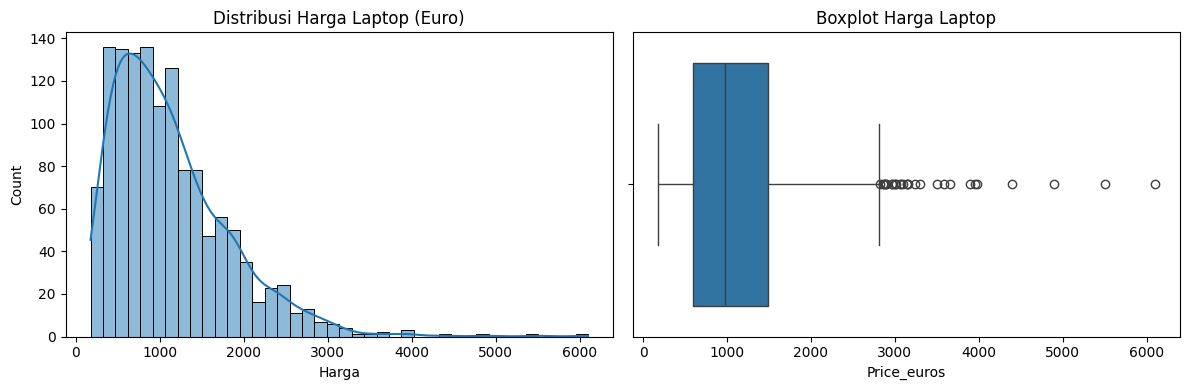

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

# Histogram Harga
plt.subplot(1, 2, 1)
sns.histplot(df['Price_euros'], bins=40, kde=True)
plt.title('Distribusi Harga Laptop (Euro)')
plt.xlabel('Harga')

# Boxplot Harga
plt.subplot(1, 2, 2)
sns.boxplot(x=df['Price_euros'])
plt.title('Boxplot Harga Laptop')

plt.tight_layout()
plt.show()

In [15]:
print("Contoh isi kolom Ram:", df['Ram'].unique()[:5])
print("Contoh isi kolom Weight:", df['Weight'].unique()[:5])
print("Contoh isi kolom Memory:", df['Memory'].unique()[:5])

Contoh isi kolom Ram: ['8GB' '16GB' '4GB' '2GB' '12GB']
Contoh isi kolom Weight: ['1.37kg' '1.34kg' '1.86kg' '1.83kg' '2.1kg']
Contoh isi kolom Memory: ['128GB SSD' '128GB Flash Storage' '256GB SSD' '512GB SSD' '500GB HDD']


TAHAP 2: PREPROCESSING (PEMBERSIHAN DATA)

In [16]:
# Ubah "8GB" -> 8
df['Ram_GB'] = df['Ram'].astype(str).str.replace('GB', '', regex=False).astype(int)

# Ubah "1.37kg" -> 1.37
df['Weight_kg'] = df['Weight'].astype(str).str.replace('kg', '', regex=False).astype(float)

print("Berhasil dibersihkan!")
print(df[['Ram', 'Ram_GB', 'Weight', 'Weight_kg']].head())

Berhasil dibersihkan!
    Ram  Ram_GB  Weight  Weight_kg
0   8GB       8  1.37kg       1.37
1   8GB       8  1.34kg       1.34
2   8GB       8  1.86kg       1.86
3  16GB      16  1.83kg       1.83
4   8GB       8  1.37kg       1.37


In [17]:
import re

def parse_screen(res):
    res = str(res)
    touch = 1 if 'Touchscreen' in res else 0
    ips = 1 if 'IPS' in res else 0
    m = re.search(r'(\d+)x(\d+)', res)
    w, h = (int(m.group(1)), int(m.group(2))) if m else (0, 0)
    return touch, ips, w, h

df[['Touchscreen', 'IPS', 'Res_W', 'Res_H']] = df['ScreenResolution'].apply(
    lambda x: pd.Series(parse_screen(x))
)
print("ScreenResolution berhasil dipecah.")

ScreenResolution berhasil dipecah.


In [18]:
def parse_memory(mem):
    mem = str(mem)
    total_gb = 0.0
    has_ssd = 0
    has_hdd = 0

    # Ambil angka dan satuan
    for val, unit in re.findall(r'(\d+\.?\d*)\s*(GB|TB)', mem):
        v = float(val)
        total_gb += v * 1024 if unit == 'TB' else v

    if 'SSD' in mem: has_ssd = 1
    if 'HDD' in mem: has_hdd = 1
    return total_gb, has_ssd, has_hdd

df[['Storage_GB', 'Has_SSD', 'Has_HDD']] = df['Memory'].apply(
    lambda x: pd.Series(parse_memory(x))
)
print("Memory berhasil dipecah.")

Memory berhasil dipecah.


In [19]:
def parse_cpu(cpu):
    m = re.search(r'(\d+\.?\d*)\s*GHz', str(cpu))
    return float(m.group(1)) if m else np.nan

df['CPU_GHz'] = df['Cpu'].apply(parse_cpu)
# Isi yang kosong dengan nilai tengah (median)
df['CPU_GHz'] = df['CPU_GHz'].fillna(df['CPU_GHz'].median())
print("CPU berhasil diambil kecepatannya.")

CPU berhasil diambil kecepatannya.


In [20]:
import numpy as np
# Log transform untuk mengurangi skewness
df['LogPrice'] = np.log1p(df['Price_euros'])
print("Harga berhasil ditransformasi ke Log.")

Harga berhasil ditransformasi ke Log.


TAHAP 3: SIMPAN DATA BERSIH

In [21]:
# Simpan dataset yang sudah dibersihkan
df.to_csv('data_bersih_laptop.csv', index=False)

print("=== SELESAI ===")
print("Bentuk data awal: (1303, 13)")
print("Bentuk data sekarang:", df.shape)

=== SELESAI ===
Bentuk data awal: (1303, 13)
Bentuk data sekarang: (1303, 24)
